# ES 335: Machine Learning Course Project
## Cost-Aware Credit Card Default Prediction
**Team:** Anant Shukla (25110030) & Jay R. Glasswala (25110147)  
**Course:** ES 335 &bull; **Dataset:** UCI Default of Credit Card Clients (Taiwan 2005)

---
### What's in this notebook
1. **Correlation of the six bill columns** (training set only).
2. **Variance Inflation Factors (VIF)** for the bill columns.
3. **Ridge vs. Lasso regularization paths** on the bill columns.
4. **What our fitted linear models actually did**, plus the bootstrap stability check.
5. **Permutation feature importance** for HistGradientBoosting.
6. **Conclusions.**

Run `python run_all.py` first: this notebook reads the files it saves in `data/processed/`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

# Load processed training data
data_path = os.path.join('..', 'data', 'processed', 'train.csv')
train_df = pd.read_csv(data_path)
print(f'Training Set Loaded: {train_df.shape[0]} rows, {train_df.shape[1]} columns')
print(f'Default Base Rate: {train_df["default"].mean():.4f} ({train_df["default"].mean()*100:.2f}%)')

Training Set Loaded: 23972 rows, 24 columns
Default Base Rate: 0.2213 (22.13%)


### 1. Collinearity of Monthly Bill Amounts (BILL_AMT1 to BILL_AMT6)
Let's inspect the correlation matrix among the six billing months on the training partition.

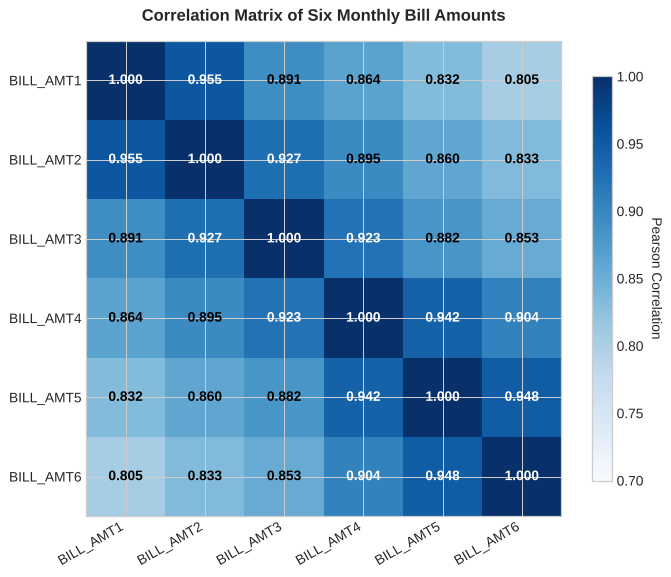

In [2]:
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
bill_corr = train_df[bill_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
cax = ax.imshow(bill_corr, cmap='Blues', vmin=0.7, vmax=1.0)
cbar = fig.colorbar(cax, shrink=0.85)
cbar.ax.set_ylabel('Pearson Correlation', rotation=270, labelpad=15)

for (i, j), z in np.ndenumerate(bill_corr):
    ax.text(j, i, f'{z:.3f}', ha='center', va='center', 
            color='white' if z > 0.9 else 'black', fontweight='bold')

ax.set_xticks(range(6))
ax.set_yticks(range(6))
ax.set_xticklabels(bill_cols, rotation=30, ha='right')
ax.set_yticklabels(bill_cols)
ax.set_title('Correlation Matrix of Six Monthly Bill Amounts', pad=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 2. Variance Inflation Factors (VIF)
A VIF > 5 or 10 signals problematic multicollinearity that destabilizes standard OLS and unregularized logistic regression.

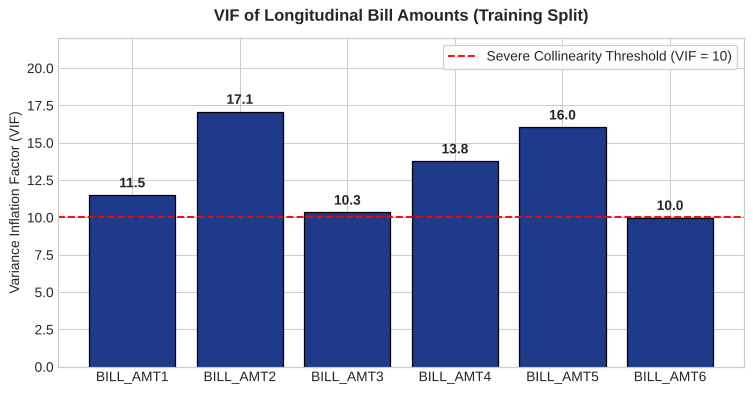

In [3]:
import json
with open(os.path.join('..', 'data', 'processed', 'collinearity_report.json')) as f:
    collin_rep = json.load(f)

vif_df = pd.DataFrame(list(collin_rep['bill_vif'].items()), columns=['Feature', 'VIF'])
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(vif_df['Feature'], vif_df['VIF'], color='#1e3a8a', edgecolor='black')
ax.axhline(10, color='red', linestyle='--', linewidth=1.5, label='Severe Collinearity Threshold (VIF = 10)')
ax.set_ylabel('Variance Inflation Factor (VIF)')
ax.set_title('VIF of Longitudinal Bill Amounts (Training Split)', pad=14, fontweight='bold')
ax.set_ylim(0, 22)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='#cccccc')
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

### 3. Ridge vs. Lasso regularization paths
How do the two penalties treat the six correlated bill columns as the penalty gets stronger (smaller $C$)?

**Note:** to keep the picture readable, this fits a logistic regression on **only the six bill columns**. Our real models use all 23 inputs, so their weights are different (see section 4). The dashed line marks the $C$ that cross-validation picked for the full models.

BILL_AMT1: non-zero for C >= 0.0070
BILL_AMT2: non-zero for C >= 0.0785
BILL_AMT3: non-zero for C >= 0.0483
BILL_AMT4: non-zero for C >= 0.8859
BILL_AMT5: non-zero for C >= 0.1274
BILL_AMT6: non-zero for C >= 0.0183


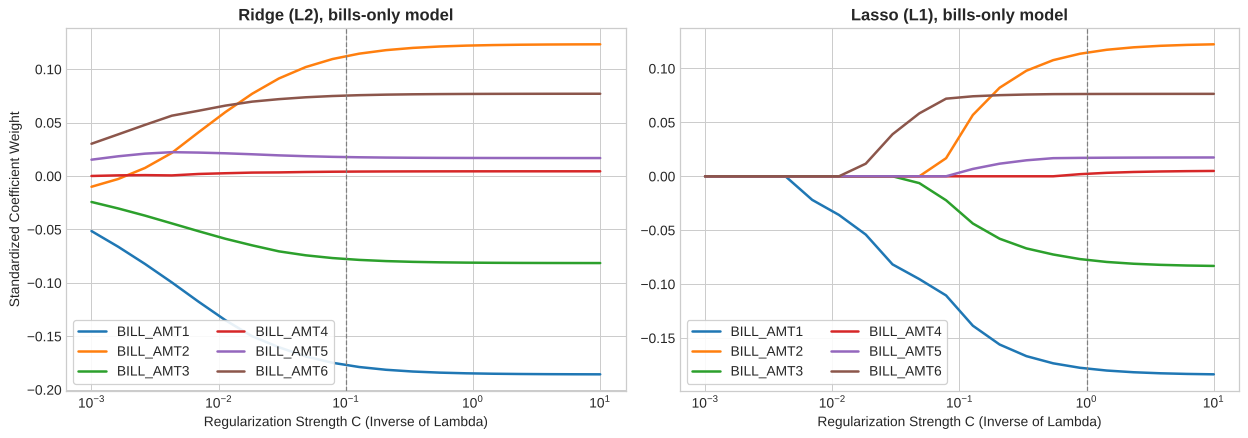

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_bills = scaler.fit_transform(train_df[bill_cols])
y = train_df['default'].values

C_values = np.logspace(-3, 1, 20)
ridge_coefs = []
lasso_coefs = []

for C in C_values:
    r_mod = LogisticRegression(penalty='l2', C=C, solver='lbfgs', max_iter=300).fit(X_bills, y)
    l_mod = LogisticRegression(penalty='l1', C=C, solver='saga', max_iter=300, random_state=42).fit(X_bills, y)
    ridge_coefs.append(r_mod.coef_[0])
    lasso_coefs.append(l_mod.coef_[0])

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for i, col in enumerate(bill_cols):
    ax1.plot(C_values, ridge_coefs[:, i], label=col, linewidth=2)
    ax2.plot(C_values, lasso_coefs[:, i], label=col, linewidth=2)

ax1.set_xscale('log')
ax1.axvline(0.1, color='grey', linestyle='--', linewidth=1)
ax1.set_title('Ridge (L2), bills-only model', fontweight='bold')
ax1.set_xlabel('Regularization Strength C (Inverse of Lambda)')
ax1.set_ylabel('Standardized Coefficient Weight')
ax1.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, edgecolor='#cccccc', ncol=2)

ax2.set_xscale('log')
ax2.axvline(1.0, color='grey', linestyle='--', linewidth=1)
ax2.set_title('Lasso (L1), bills-only model', fontweight='bold')
ax2.set_xlabel('Regularization Strength C (Inverse of Lambda)')
ax2.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, edgecolor='#cccccc', ncol=2)
plt.tight_layout()
plt.show()
# where does each Lasso weight become exactly zero?
for i, col in enumerate(bill_cols):
    nonzero = C_values[np.abs(lasso_coefs[:, i]) > 1e-8]
    print(f"{col}: non-zero for C >= {nonzero.min():.4f}" if len(nonzero) else f"{col}: zero for every C")


**What the paths show:** Ridge shrinks all six weights smoothly toward zero but never sets one exactly to zero. Lasso drops months one by one as the penalty grows, and at strong penalties only `BILL_AMT1` is left.

### 4. What our fitted linear models actually did
The paths above are for a bills-only model. Here are the bill weights of the real models (all 23 inputs, penalties chosen by 5-fold CV), and the bootstrap check from `src/robustness_checks.py` (100 refits on resampled training data).

In [5]:
import joblib

models = joblib.load(os.path.join('..', 'data', 'processed', 'trained_models.joblib'))
rows = {}
for name in ['plain_logistic', 'ridge_logistic', 'lasso_logistic', 'elastic_net']:
    pipe = models[name]
    names = [n.split('__')[-1] for n in pipe.named_steps['preprocessor'].get_feature_names_out()]
    coef = pd.Series(pipe.named_steps['classifier'].coef_[0], index=names)
    rows[name] = coef[bill_cols].round(3)
fitted = pd.DataFrame(rows).T
print("Bill weights of the fitted models (standardized features):")
print(fitted.to_string())

with open(os.path.join('..', 'data', 'processed', 'robustness_checks.json')) as f:
    stab = json.load(f)['coefficient_stability']
summary = pd.DataFrame({
    'Ridge mean weight': {c: stab['ridge_C0.1'][c]['mean'] for c in bill_cols},
    'Ridge 95% range': {c: str(stab['ridge_C0.1'][c]['ci95']) for c in bill_cols},
    'Ridge % positive': {c: int(100 * stab['ridge_C0.1'][c]['share_positive']) for c in bill_cols},
    'Lasso C=1 % zero': {c: int(100 * stab['lasso_C1.0'][c]['share_zero']) for c in bill_cols},
    'Lasso C=0.01 % zero': {c: int(100 * stab['lasso_C0.01'][c]['share_zero']) for c in bill_cols},
})
print("\nBootstrap stability (100 refits):")
print(summary.to_string())

Bill weights of the fitted models (standardized features):
                BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  BILL_AMT6
plain_logistic     -0.469      0.304     -0.030     -0.005      0.033      0.064
ridge_logistic     -0.416      0.237     -0.008     -0.016      0.025      0.074
lasso_logistic     -0.442      0.258     -0.005      0.000      0.020      0.066
elastic_net        -0.348      0.156      0.000      0.000      0.018      0.067

Bootstrap stability (100 refits):
           Ridge mean weight   Ridge 95% range  Ridge % positive  Lasso C=1 % zero  Lasso C=0.01 % zero
BILL_AMT1             -0.405  [-0.605, -0.252]                 0                 0                    0
BILL_AMT2              0.212    [-0.019, 0.47]                94                 3                  100
BILL_AMT3              0.000     [-0.228, 0.2]                52                11                   97
BILL_AMT4             -0.011   [-0.191, 0.157]                47                 5   

### 5. Permutation feature importance (HistGradientBoosting)
Drop in test PR-AUC when one input column is shuffled (10 repeats). Computed in `src/error_analysis.py` and read from `data/processed/error_analysis.json`.

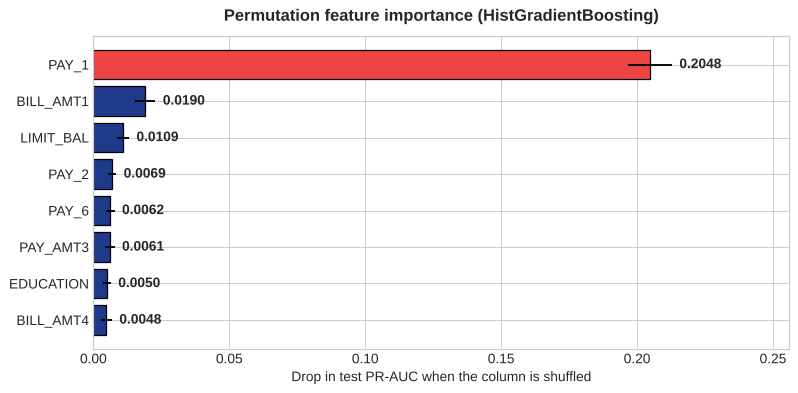

In [6]:
with open(os.path.join('..', 'data', 'processed', 'error_analysis.json')) as f:
    importance = json.load(f)['permutation_importance']
features = [d['feature'] for d in importance]
drops = [d['mean_drop'] for d in importance]
errs = [d['std'] for d in importance]

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#ef4444' if f == 'PAY_1' else '#1e3a8a' for f in features]
bars = ax.barh(features[::-1], drops[::-1], xerr=errs[::-1], color=colors[::-1], edgecolor='black')
ax.set_xlim(0, max(drops) * 1.25)
ax.set_xlabel('Drop in test PR-AUC when the column is shuffled')
ax.set_title('Permutation feature importance (HistGradientBoosting)', pad=12, fontweight='bold')
for bar, err in zip(bars, errs[::-1]):
    width = bar.get_width()
    ax.annotate(f'{width:.4f}', xy=(width + err, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords='offset points', ha='left', va='center', fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Conclusions
* The six bill columns are strongly correlated (up to $r \approx 0.95$, VIFs up to about 17).
* In every fitted linear model, `BILL_AMT1` gets a large negative weight and `BILL_AMT2` a positive one. Since the two columns are almost the same, the model is effectively using the change in balance from August to September. These two weights are stable across bootstrap refits; `BILL_AMT3`–`BILL_AMT5` flip sign in about half of them, so their individual weights shouldn't be interpreted.
* Cross-validation picked a weak Lasso penalty ($C = 1.0$), so the fitted Lasso keeps almost all bill months. Only at much stronger penalties does Lasso drop the other months and keep only `BILL_AMT1`.
* All four linear models reach almost the same test PR-AUC (about 0.503): regularization changes the weights much more than the predictions.
* For HistGradientBoosting, September's repayment status (`PAY_1`) is by far the most important input, about ten times more than any other column.